# TrustGuard Notebook 02: Toxicity Modeling, Multi-Label Analysis, and Error Review

**Purpose:** build a real toxicity-classification baseline that complements Notebook 01's SMS spam model. This notebook is standalone and designed for Google Colab. It does not require cloning the TrustGuard repository or using an external LLM API.

## What this experiment covers

1. Load the public Civil Comments Parquet splits from Hugging Face.
2. Inspect continuous crowd-label scores and define an explicit, configurable binary-label rule.
3. Use the dataset's official train/validation/test partitions, bounded samples for Colab, and duplicate checks to reduce evaluation leakage.
4. Compare word-only TF-IDF + Logistic Regression with word-and-character TF-IDF + Logistic Regression for the primary toxicity task.
5. Select an operating threshold on validation data only; evaluate once on the held-out test sample.
6. Train independent classifiers for six toxicity subtypes and report per-label metrics.
7. Inspect errors, save a TrustGuard-compatible binary toxicity model artifact, and export aggregate reports.

**Important:** this is still a classical ML benchmark, not the finished agentic moderation system. It is a deliberate baseline against which later transformer models and contextual agents can be compared.

> Run cells from top to bottom. The initial data download is large (about 422 MB compressed for the whole dataset). The default sample sizes are chosen for a standard Colab CPU runtime. Keep the source dataset and row-level error examples out of public Git commits.

## 1. Dataset choice, labels, and limitations

We use [Google's Civil Comments dataset card](https://huggingface.co/datasets/google/civil_comments). Its public card describes comments from the Civil Comments archive (2015–2017), with crowd-annotated scores for `toxicity`, `severe_toxicity`, `obscene`, `threat`, `insult`, `identity_attack`, and `sexual_explicit`. The card lists the data under **CC0 1.0**. We will keep the source attribution in the model card even though the listed license is CC0.

Each label is a score between 0 and 1 representing the fraction of annotators who assigned that attribute. For this experiment we define `score >= 0.5` as a positive label. This threshold is a modeling choice, not a universal definition of toxicity; we will make it visible and test thresholds using the validation split.

**Limitations:** the dataset is English-language, historical, and sourced from news-site comments. It does not represent every platform or community. This basic release provides the seven toxicity-related targets, but not the full identity-group annotation set needed for a complete subgroup fairness benchmark. We will design a separate bias/robustness evaluation before making any fairness claims. See the [TensorFlow Datasets description](https://www.tensorflow.org/datasets/catalog/civil_comments) for additional context and known concerns around parent-comment metadata.

## 2. Install dependencies

This is a standalone Colab notebook. It downloads the data and uses scikit-learn; no GPU or hosted AI API is required.

In [2]:
%pip install -q \
    "pandas==2.2.3" \
    "huggingface_hub>=1.32.0,<2.0" \
    pyarrow \
    scikit-learn \
    joblib \
    matplotlib

In [3]:
from pathlib import Path
import json, os, re, time, warnings, zipfile
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from huggingface_hub import hf_hub_download
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.pipeline import FeatureUnion, Pipeline

SEED = 42
LABEL_SCORE_THRESHOLD = 0.50
MIN_VALIDATION_PRECISION = 0.70

# Colab-safe sample sizes. Reduce these first if your runtime runs low on memory.
TRAIN_SAMPLE_SIZE = 60_000
VALIDATION_SAMPLE_SIZE = 15_000
TEST_SAMPLE_SIZE = 15_000

DATASET_REPO = "google/civil_comments"
DATASET_REVISION = "refs/convert/parquet"  # Hub's Parquet conversion branch
DATASET_CARD_URL = "https://huggingface.co/datasets/google/civil_comments"
DATASET_LICENSE = "CC0 1.0 (as listed on the Hugging Face dataset card)"

LABEL_COLUMNS = [
    "toxicity", "severe_toxicity", "obscene", "threat",
    "insult", "identity_attack", "sexual_explicit",
]
DATA_COLUMNS = ["text", *LABEL_COLUMNS]
OUTPUT_DIR = Path("/content/trustguard_toxicity_output")
MODEL_DIR = OUTPUT_DIR / "models"
REPORT_DIR = OUTPUT_DIR / "reports"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Python environment ready")
print("Dataset:", DATASET_REPO)
print("Label score threshold:", LABEL_SCORE_THRESHOLD)
print("Sample sizes:", TRAIN_SAMPLE_SIZE, VALIDATION_SAMPLE_SIZE, TEST_SAMPLE_SIZE)

Python environment ready
Dataset: google/civil_comments
Label score threshold: 0.5
Sample sizes: 60000 15000 15000


## 3. Download the official train, validation, and test Parquet files

The Hub's Parquet-conversion branch has separate train, validation, and test files. We use those predefined partitions rather than creating a random split from the entire dataset. The train partition is sampled for Colab efficiency; the validation and test partitions remain separate for threshold selection and final evaluation.

In [4]:
def download_parquet(split: str, filename: str) -> str:
    """Download one publicly available Parquet file from the dataset repository."""
    return hf_hub_download(
        repo_id=DATASET_REPO,
        repo_type="dataset",
        revision=DATASET_REVISION,
        filename=f"default/{split}/{filename}",
    )

DATA_FILES = {
    "train": ["0000.parquet", "0001.parquet"],
    "validation": ["0000.parquet"],
    "test": ["0000.parquet"],
}

local_paths = {}
for split_name, filenames in DATA_FILES.items():
    local_paths[split_name] = [download_parquet(split_name, name) for name in filenames]
    print(f"{split_name}: downloaded {len(local_paths[split_name])} file(s)")

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/train/0001.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

default/train/0001.parquet: downloading bytes:           |  0.00B            

train: downloaded 2 file(s)


...

default/validation/0000.parquet: downloading bytes:           |  0.00B            

validation: downloaded 1 file(s)


default/test/0000.parquet: reconstructing file:   0%|          |  0.00B / 20.8MB            

default/test/0000.parquet: downloading bytes:           |  0.00B            

test: downloaded 1 file(s)


In [5]:
# Read only the text and seven target columns to limit memory use.
raw_splits = {}
for split_name, paths in local_paths.items():
    frames = [pd.read_parquet(path, columns=DATA_COLUMNS) for path in paths]
    frame = pd.concat(frames, ignore_index=True) if len(frames) > 1 else frames[0]
    raw_splits[split_name] = frame
    print(f"{split_name}: {len(frame):,} rows; {frame.memory_usage(deep=True).sum() / (1024**2):,.1f} MiB in DataFrame memory")

print("\nSplit sizes:")
display(pd.DataFrame({"split": list(raw_splits), "rows": [len(v) for v in raw_splits.values()]}))
display(raw_splits["train"].head(3))

train: 1,804,874 rows; 681.9 MiB in DataFrame memory
validation: 97,320 rows; 36.9 MiB in DataFrame memory
test: 97,320 rows; 36.6 MiB in DataFrame memory

Split sizes:


,split,rows
0,train,1804874
1,validation,97320
2,test,97320


,text,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,"This is so cool. It's like, 'would you want yo...",0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Thank you!! This would make my life a lot less...,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,This is such an urgent design problem; kudos t...,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Understand the label distribution

The target fields are fractional annotator scores. The first target is overall toxicity; the remaining six are subtype signals. We convert each score into a binary label only for this baseline, using the documented threshold above. Do not interpret a model score as a perfectly calibrated probability.

In [6]:
def bounded_stratified_sample(df: pd.DataFrame, n_rows: int, seed: int) -> pd.DataFrame:
    """Take a reproducible bounded sample stratified on the primary toxicity target."""
    if len(df) <= n_rows:
        return df.copy().reset_index(drop=True)
    y = (df["toxicity"].astype(float) >= LABEL_SCORE_THRESHOLD).astype(int).to_numpy()
    splitter = StratifiedShuffleSplit(n_splits=1, train_size=n_rows, random_state=seed)
    chosen_idx, _ = next(splitter.split(np.zeros(len(df)), y))
    return df.iloc[chosen_idx].copy().reset_index(drop=True)

sampled = {
    "train": bounded_stratified_sample(raw_splits["train"], TRAIN_SAMPLE_SIZE, SEED),
    "validation": bounded_stratified_sample(raw_splits["validation"], VALIDATION_SAMPLE_SIZE, SEED + 1),
    "test": bounded_stratified_sample(raw_splits["test"], TEST_SAMPLE_SIZE, SEED + 2),
}

for name, frame in sampled.items():
    frame["text"] = frame["text"].fillna("").astype(str)
    for col in LABEL_COLUMNS:
        frame[col] = pd.to_numeric(frame[col], errors="coerce")
    frame.dropna(subset=LABEL_COLUMNS, inplace=True)
    frame = frame[frame["text"].str.strip().ne("")].copy()
    sampled[name] = frame.reset_index(drop=True)

prevalence = []
for label in LABEL_COLUMNS:
    row = {"label": label}
    for split_name, frame in sampled.items():
        binary = frame[label] >= LABEL_SCORE_THRESHOLD
        row[f"{split_name}_positive_rate"] = float(binary.mean())
        row[f"{split_name}_positive_count"] = int(binary.sum())
    prevalence.append(row)
prevalence_df = pd.DataFrame(prevalence)
display(prevalence_df.style.format({c: "{:.2%}" for c in prevalence_df.columns if c.endswith("positive_rate")}))

,label,train_positive_rate,train_positive_count,validation_positive_rate,validation_positive_count,test_positive_rate,test_positive_count
0,toxicity,8.00%,4798,7.88%,1182,7.99%,1199
1,severe_toxicity,0.00%,0,0.00%,0,0.00%,0
2,obscene,0.55%,330,0.54%,81,0.62%,93
3,threat,0.22%,132,0.25%,38,0.18%,27
4,insult,5.86%,3516,5.93%,889,6.01%,901
5,identity_attack,0.73%,435,0.61%,92,0.73%,110
6,sexual_explicit,0.27%,165,0.16%,24,0.19%,29


## 5. Reduce duplicate leakage and prepare binary labels

Some comments may repeat after case-folding and whitespace normalization. We remove repeated normalized text within a split. If a normalized message appears in more than one split, we remove that text from *all* sampled splits, preventing a duplicate from appearing in training and evaluation. We also remove within-split duplicate groups whose binary label vectors disagree.

This is a bounded-sample audit rather than a claim that we deduplicated every row in the full corpus. The full source's published splits remain the base partitions.

In [7]:
def normalize_text(value: str) -> str:
    return " ".join(str(value).casefold().split())

for frame in sampled.values():
    frame["_norm"] = frame["text"].map(normalize_text)
    frame["_binary_signature"] = frame[LABEL_COLUMNS].ge(LABEL_SCORE_THRESHOLD).astype("uint8").astype(str).agg("".join, axis=1)

# Drop any normalized text appearing in multiple sampled splits from every split.
norm_sets = {name: set(frame["_norm"]) for name, frame in sampled.items()}
cross_split = (norm_sets["train"] & norm_sets["validation"]) | (norm_sets["train"] & norm_sets["test"]) | (norm_sets["validation"] & norm_sets["test"])
removed_cross_split = len(cross_split)

cleaned = {}
within_dups_removed = {}
conflict_groups_removed = {}
for name, frame in sampled.items():
    before = len(frame)
    frame = frame[~frame["_norm"].isin(cross_split)].copy()
    # If identical normalized text has conflicting binarized label vectors, exclude that group.
    label_counts = frame.groupby("_norm")["_binary_signature"].nunique()
    conflicting_norms = set(label_counts[label_counts > 1].index)
    conflict_groups_removed[name] = len(conflicting_norms)
    frame = frame[~frame["_norm"].isin(conflicting_norms)].copy()
    before_dedup = len(frame)
    frame = frame.drop_duplicates(subset="_norm", keep="first").copy()
    within_dups_removed[name] = before_dedup - len(frame)
    frame.drop(columns=["_norm", "_binary_signature"], inplace=True)
    cleaned[name] = frame.reset_index(drop=True)
    print(f"{name}: {before:,} sampled -> {len(frame):,} after duplicate checks")

sampled = cleaned
leakage_audit = {
    "cross_split_normalized_text_groups_removed_from_all_splits": int(removed_cross_split),
    "within_split_duplicate_rows_removed": {k: int(v) for k, v in within_dups_removed.items()},
    "conflicting_binary_label_groups_removed": {k: int(v) for k, v in conflict_groups_removed.items()},
}
display(pd.DataFrame([
    {"split": split_name, "rows_after_checks": len(frame), **{col: int((frame[col] >= LABEL_SCORE_THRESHOLD).sum()) for col in LABEL_COLUMNS}}
    for split_name, frame in sampled.items()
]).set_index("split"))

train: 60,000 sampled -> 59,721 after duplicate checks
validation: 15,000 sampled -> 14,905 after duplicate checks
test: 15,000 sampled -> 14,899 after duplicate checks


,rows_after_checks,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
split,,,,,,,,
train,59721,4786,0,329,132,3509,435,164
validation,14905,1174,0,79,38,880,91,23
test,14899,1191,0,90,27,895,108,29


In [8]:
train_df, val_df, test_df = sampled["train"], sampled["validation"], sampled["test"]
X_train_text = train_df["text"].tolist()
X_val_text = val_df["text"].tolist()
X_test_text = test_df["text"].tolist()

y_train = (train_df[LABEL_COLUMNS] >= LABEL_SCORE_THRESHOLD).astype("int8")
y_val = (val_df[LABEL_COLUMNS] >= LABEL_SCORE_THRESHOLD).astype("int8")
y_test = (test_df[LABEL_COLUMNS] >= LABEL_SCORE_THRESHOLD).astype("int8")

assert not set(train_df["text"].map(normalize_text)) & set(val_df["text"].map(normalize_text))
assert not set(train_df["text"].map(normalize_text)) & set(test_df["text"].map(normalize_text))
assert not set(val_df["text"].map(normalize_text)) & set(test_df["text"].map(normalize_text))
assert len(set(y_train["toxicity"])) == 2
print("Leakage checks passed for normalized text across the sampled splits.")

Leakage checks passed for normalized text across the sampled splits.


## 6. Define two comparable primary-toxicity baselines

Both candidates use Logistic Regression so the comparison isolates representation choice:

- **Word TF-IDF:** word unigrams and bigrams.
- **Word + character TF-IDF:** word unigrams/bigrams plus character n-grams, which can help with misspellings, obfuscation, and morphological variants.

We use class weighting for the imbalanced labels. These remain transparent baseline models; later experiments can compare them with a pretrained transformer.

In [9]:
def make_word_pipeline() -> Pipeline:
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True, strip_accents="unicode", ngram_range=(1, 2),
            min_df=3, max_features=45_000, sublinear_tf=True, dtype=np.float32,
        )),
        ("classifier", LogisticRegression(
            C=2.0, class_weight="balanced", max_iter=500,
            solver="liblinear", random_state=SEED,
        )),
    ])


def make_word_char_pipeline() -> Pipeline:
    features = FeatureUnion([
        ("word", TfidfVectorizer(
            lowercase=True, strip_accents="unicode", ngram_range=(1, 2),
            min_df=3, max_features=35_000, sublinear_tf=True, dtype=np.float32,
        )),
        ("char", TfidfVectorizer(
            analyzer="char_wb", ngram_range=(3, 5), min_df=3,
            max_features=35_000, sublinear_tf=True, dtype=np.float32,
        )),
    ])
    return Pipeline([
        ("features", features),
        ("classifier", LogisticRegression(
            C=2.0, class_weight="balanced", max_iter=500,
            solver="liblinear", random_state=SEED,
        )),
    ])


def choose_threshold(y_true, probabilities, precision_floor=MIN_VALIDATION_PRECISION):
    """Select a threshold using validation data only; maximize F1 subject to a precision floor."""
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    candidates = []
    for threshold in np.round(np.arange(0.05, 0.951, 0.01), 2):
        preds = (probabilities >= threshold).astype(int)
        precision = precision_score(y_true, preds, zero_division=0)
        recall = recall_score(y_true, preds, zero_division=0)
        f1 = f1_score(y_true, preds, zero_division=0)
        macro_f1 = f1_score(y_true, preds, average="macro", zero_division=0)
        candidates.append({
            "threshold": float(threshold), "precision": float(precision),
            "recall": float(recall), "f1": float(f1), "macro_f1": float(macro_f1),
        })
    eligible = [item for item in candidates if item["precision"] >= precision_floor]
    pool = eligible if eligible else candidates
    best = max(pool, key=lambda item: (item["macro_f1"], item["f1"], item["precision"]))
    best = dict(best)
    best["precision_floor_met"] = bool(eligible)
    return best


def evaluate_binary(y_true, probabilities, threshold):
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    y_pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "n": int(len(y_true)),
        "positive_support": int(y_true.sum()),
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "false_positive_rate": float(fp / max(1, fp + tn)),
        "roc_auc": float(roc_auc_score(y_true, probabilities)) if len(np.unique(y_true)) == 2 else None,
        "average_precision": float(average_precision_score(y_true, probabilities)) if y_true.sum() > 0 else None,
        "confusion_matrix": [[int(tn), int(fp)], [int(fn), int(tp)]],
    }

In [10]:
primary = "toxicity"
candidates = {
    "word_tfidf_logistic_regression": make_word_pipeline(),
    "word_char_tfidf_logistic_regression": make_word_char_pipeline(),
}

candidate_objects = {}
validation_rows = []
for name, pipeline in candidates.items():
    start = time.time()
    print(f"Training {name} ...")
    pipeline.fit(X_train_text, y_train[primary].to_numpy())
    val_probs = pipeline.predict_proba(X_val_text)[:, 1]
    threshold_info = choose_threshold(y_val[primary].to_numpy(), val_probs)
    val_metrics = evaluate_binary(y_val[primary].to_numpy(), val_probs, threshold_info["threshold"])
    validation_rows.append({
        "model": name,
        "validation_threshold": threshold_info["threshold"],
        "validation_precision": val_metrics["precision"],
        "validation_recall": val_metrics["recall"],
        "validation_f1": val_metrics["f1"],
        "validation_macro_f1": val_metrics["macro_f1"],
        "validation_average_precision": val_metrics["average_precision"],
        "precision_floor_met": threshold_info["precision_floor_met"],
        "fit_seconds": round(time.time() - start, 1),
    })
    candidate_objects[name] = {
        "pipeline": pipeline,
        "val_probabilities": val_probs,
        "threshold_info": threshold_info,
        "val_metrics": val_metrics,
    }

validation_comparison = pd.DataFrame(validation_rows).sort_values("validation_macro_f1", ascending=False).reset_index(drop=True)
display(validation_comparison)

Training word_tfidf_logistic_regression ...
Training word_char_tfidf_logistic_regression ...


,model,validation_threshold,validation_precision,validation_recall,validation_f1,validation_macro_f1,validation_average_precision,precision_floor_met,fit_seconds
0,word_char_tfidf_logistic_regression,0.80,0.722067,0.440375,0.547090,0.758215,0.626693,True,86.0
1,word_tfidf_logistic_regression,0.74,0.702096,0.399489,0.509229,0.738453,0.589151,True,24.8


## 7. Select on validation data, then evaluate on the held-out test sample

Model selection uses **validation macro-F1** after choosing each candidate's threshold using validation data. The held-out test sample must not be used to pick the model or threshold.

In [11]:
selected_model_name = str(validation_comparison.iloc[0]["model"])
selected = candidate_objects[selected_model_name]
selected_pipeline = selected["pipeline"]
selected_threshold_info = selected["threshold_info"]
selected_threshold = float(selected_threshold_info["threshold"])

# This is the first use of the held-out test labels for model evaluation.
test_probabilities = selected_pipeline.predict_proba(X_test_text)[:, 1]
test_metrics = evaluate_binary(y_test[primary].to_numpy(), test_probabilities, selected_threshold)

print("Selected model:", selected_model_name)
print("Threshold selected using validation only:", selected_threshold)
print("\nHeld-out primary toxicity test metrics:")
display(pd.DataFrame([test_metrics]).T.rename(columns={0: "value"}))
print("\nClassification report at selected threshold:")
print(classification_report(
    y_test[primary].to_numpy(),
    (test_probabilities >= selected_threshold).astype(int),
    labels=[0, 1], target_names=["non-toxic", "toxic"], zero_division=0,
))

Selected model: word_char_tfidf_logistic_regression
Threshold selected using validation only: 0.8

Held-out primary toxicity test metrics:


,value
n,14899
positive_support,1191
threshold,0.8
accuracy,0.940533
balanced_accuracy,0.710462
precision,0.707483
recall,0.436608
f1,0.539979
macro_f1,0.754096
false_positive_rate,0.015684



Classification report at selected threshold:
              precision    recall  f1-score   support

   non-toxic       0.95      0.98      0.97     13708
       toxic       0.71      0.44      0.54      1191

    accuracy                           0.94     14899
   macro avg       0.83      0.71      0.75     14899
weighted avg       0.93      0.94      0.93     14899



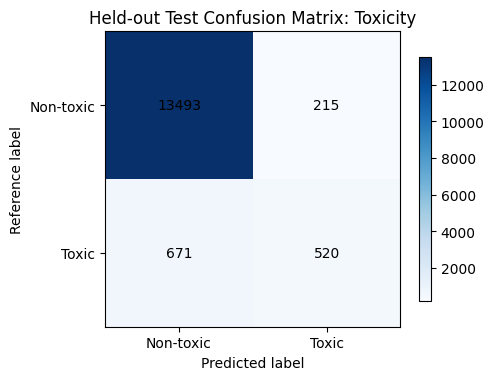

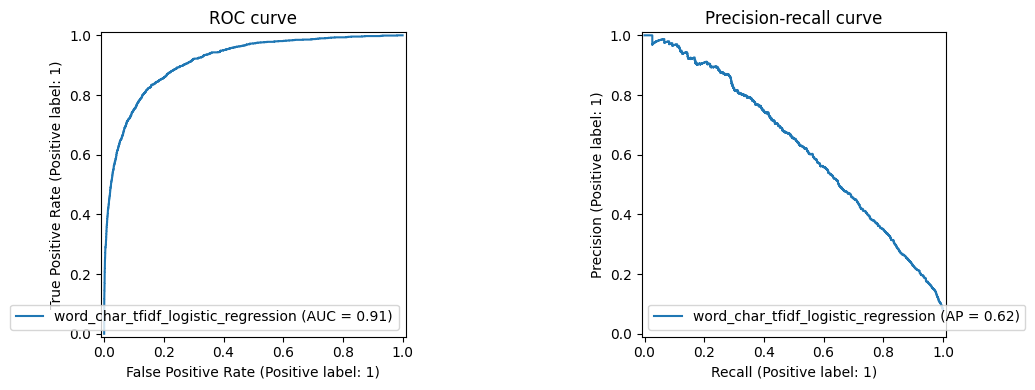

In [12]:
cm = np.asarray(test_metrics["confusion_matrix"], dtype=int)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_title("Held-out Test Confusion Matrix: Toxicity")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Reference label")
ax.set_xticks([0, 1], labels=["Non-toxic", "Toxic"])
ax.set_yticks([0, 1], labels=["Non-toxic", "Toxic"])
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center", color="black")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test[primary].to_numpy(), test_probabilities, ax=axes[0], name=selected_model_name)
PrecisionRecallDisplay.from_predictions(y_test[primary].to_numpy(), test_probabilities, ax=axes[1], name=selected_model_name)
axes[0].set_title("ROC curve")
axes[1].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

## 8. Extend to the six subtype labels

Toxicity is not a single category. We now train independent binary classifiers for the six available subtypes: severe toxicity, obscenity, threat, insult, identity attack, and sexually explicit content. These are multi-label outputs: one comment may have more than one subtype.

Each subtype uses the feature representation selected for the main toxicity task. Thresholds are selected on the validation sample per label, subject to the same precision-floor rule. The report includes support counts because rare categories can make metrics unstable.

In [13]:
subtype_labels = [label for label in LABEL_COLUMNS if label != "toxicity"]

# Reuse the selected pipeline's fitted feature transformer, rather than fitting a new vectorizer per subtype.
if "features" in selected_pipeline.named_steps:
    fitted_vectorizer = selected_pipeline.named_steps["features"]
else:
    fitted_vectorizer = selected_pipeline.named_steps["tfidf"]

print("Transforming text once for subtype models ...")
X_train_features = fitted_vectorizer.transform(X_train_text)
X_val_features = fitted_vectorizer.transform(X_val_text)
X_test_features = fitted_vectorizer.transform(X_test_text)

subtype_models = {}
label_metrics_rows = [{
    "label": "toxicity",
    "selected_threshold": selected_threshold,
    **{f"test_{k}": v for k, v in test_metrics.items() if k != "confusion_matrix"},
    "test_confusion_matrix": json.dumps(test_metrics["confusion_matrix"]),
}]

for label in subtype_labels:
    ytr = y_train[label].to_numpy(dtype=int)
    yv = y_val[label].to_numpy(dtype=int)
    yte = y_test[label].to_numpy(dtype=int)
    if len(np.unique(ytr)) < 2 or len(np.unique(yv)) < 2 or len(np.unique(yte)) < 2:
        print(f"Skipping {label}: a sampled split does not contain both classes.")
        continue
    model = LogisticRegression(
        C=2.0, class_weight="balanced", max_iter=500,
        solver="liblinear", random_state=SEED,
    )
    started = time.time()
    model.fit(X_train_features, ytr)
    val_probs = model.predict_proba(X_val_features)[:, 1]
    threshold_info = choose_threshold(yv, val_probs)
    test_probs = model.predict_proba(X_test_features)[:, 1]
    metrics = evaluate_binary(yte, test_probs, threshold_info["threshold"])
    subtype_models[label] = model
    label_metrics_rows.append({
        "label": label,
        "selected_threshold": float(threshold_info["threshold"]),
        "validation_precision_floor_met": bool(threshold_info["precision_floor_met"]),
        **{f"test_{k}": v for k, v in metrics.items() if k != "confusion_matrix"},
        "test_confusion_matrix": json.dumps(metrics["confusion_matrix"]),
        "fit_seconds": round(time.time() - started, 1),
    })
    print(f"Completed {label}: test F1={metrics['f1']:.3f}, test support={metrics['positive_support']:,}")

label_metrics = pd.DataFrame(label_metrics_rows)
display(label_metrics[[c for c in [
    "label", "selected_threshold", "test_n", "test_positive_support", "test_precision",
    "test_recall", "test_f1", "test_macro_f1", "test_false_positive_rate",
    "test_roc_auc", "test_average_precision", "validation_precision_floor_met"
] if c in label_metrics.columns]])

Transforming text once for subtype models ...
Skipping severe_toxicity: a sampled split does not contain both classes.
Completed obscene: test F1=0.436, test support=90
Completed threat: test F1=0.316, test support=27
Completed insult: test F1=0.594, test support=895
Completed identity_attack: test F1=0.264, test support=108
Completed sexual_explicit: test F1=0.231, test support=29


,label,selected_threshold,test_n,test_positive_support,test_precision,test_recall,test_f1,test_macro_f1,test_false_positive_rate,test_roc_auc,test_average_precision,validation_precision_floor_met
0,toxicity,0.80,14899,1191,0.707483,0.436608,0.539979,0.754096,0.015684,0.914438,0.624867,NaN
1,obscene,0.37,14899,90,0.418367,0.455556,0.436170,0.716295,0.003849,0.937478,0.348450,False
2,threat,0.54,14899,27,0.300000,0.333333,0.315789,0.657239,0.001412,0.955830,0.204778,False
3,insult,0.74,14899,895,0.696697,0.518436,0.594491,0.786037,0.014424,0.926455,0.644459,True
4,identity_attack,0.83,14899,108,0.292135,0.240741,0.263959,0.629530,0.004259,0.953940,0.235407,False
5,sexual_explicit,0.46,14899,29,0.260870,0.206897,0.230769,0.614712,0.001143,0.887962,0.120515,False


## 9. Error analysis and threshold interpretation

We inspect a sample of primary-toxicity mistakes. These examples contain user-generated text. Keep the full error CSV local; the downloadable public bundle below deliberately excludes row-level comment text.

Remember: the classifier score is not independently calibrated. A score of 0.8 must not be presented as an 80% real-world probability unless a separate calibration study establishes that interpretation.

In [14]:
y_test_primary = y_test[primary].to_numpy(dtype=int)
y_pred_primary = (test_probabilities >= selected_threshold).astype(int)
error_mask = y_test_primary != y_pred_primary
error_frame = pd.DataFrame({
    "text": X_test_text,
    "true_toxicity": y_test_primary,
    "predicted_toxicity": y_pred_primary,
    "model_score": test_probabilities,
    "error_type": np.where(
        (y_test_primary == 0) & (y_pred_primary == 1), "false_positive", "false_negative"
    ),
})
error_frame = error_frame.loc[error_mask].sort_values("model_score", ascending=False).reset_index(drop=True)
print(f"Primary toxicity errors: {len(error_frame):,} / {len(test_df):,} sampled test comments")
display(error_frame.head(20))

Primary toxicity errors: 886 / 14,899 sampled test comments


,text,true_toxicity,predicted_toxicity,model_score,error_type
0,Damn right,0,1,0.999796,false_positive
1,"It's not white face, its clown make up. He's ...",0,1,0.998544,false_positive
2,The dumb epidemic is getting worse.,0,1,0.997264,false_positive
3,Suckers,0,1,0.996434,false_positive
4,No. What people are saying is that Trump voter...,0,1,0.993944,false_positive
5,"Honestly Trump is amazing and not in a ""realis...",0,1,0.993035,false_positive
6,I see your white pointed hat is a little crooked.,0,1,0.992089,false_positive
7,NUKE the Rothschild-Bauer FORCED occupation of...,0,1,0.991852,false_positive
8,i love how those defending Trump blame the med...,0,1,0.990940,false_positive
9,Just when I thought I had heard every excuse p...,0,1,0.990179,false_positive


,threshold,precision,recall,f1,false_positive_rate
0,0.25,0.318318,0.812606,0.457444,0.148787
1,0.35,0.394304,0.754685,0.517977,0.099119
2,0.50,0.494852,0.655026,0.563783,0.057170
3,0.65,0.603512,0.556218,0.578901,0.031243
4,0.75,0.667063,0.477853,0.556824,0.020392


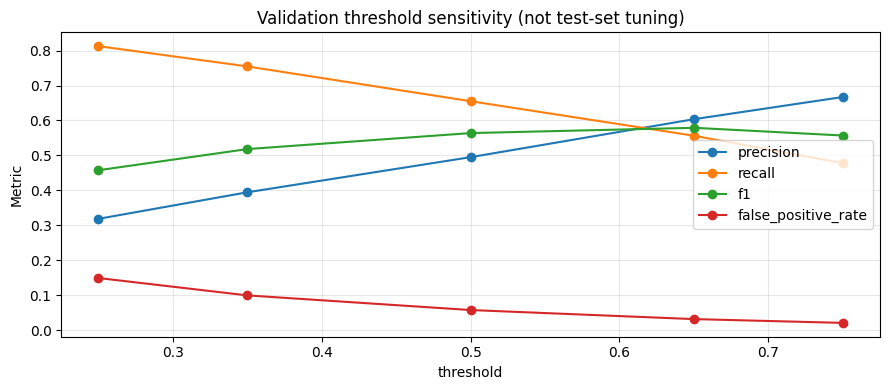

In [15]:
# Threshold sensitivity on validation data, for analysis only. The held-out test result above remains tied to the selected threshold.
val_probs_selected = selected["val_probabilities"]
y_val_primary = y_val[primary].to_numpy(dtype=int)
sensitivity_rows = []
for threshold in [0.25, 0.35, 0.50, 0.65, 0.75]:
    pred = (val_probs_selected >= threshold).astype(int)
    sensitivity_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_val_primary, pred, zero_division=0),
        "recall": recall_score(y_val_primary, pred, zero_division=0),
        "f1": f1_score(y_val_primary, pred, zero_division=0),
        "false_positive_rate": (
            confusion_matrix(y_val_primary, pred, labels=[0,1])[0,1]
            / max(1, confusion_matrix(y_val_primary, pred, labels=[0,1])[0].sum())
        ),
    })
sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df)
ax = sensitivity_df.set_index("threshold")[["precision", "recall", "f1", "false_positive_rate"]].plot(marker="o", figsize=(9,4))
ax.set_title("Validation threshold sensitivity (not test-set tuning)")
ax.set_ylabel("Metric")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Save a TrustGuard-compatible toxicity model artifact and reports

The app's current model loader expects a trusted `joblib` dictionary with `format_version=1`, `task="toxicity"`, an estimator with `predict_proba`, a decision threshold, and metadata. We save the selected **binary primary toxicity pipeline** in that format.

Subtype estimators are analyzed and reported here, but the current application loader does not yet consume a multi-label bundle. We will update the application separately if we decide to expose all subtype predictions.

In [17]:
MODEL_PATH = MODEL_DIR / "toxicity_classifier.joblib"
EVALUATION_PATH = REPORT_DIR / "toxicity_evaluation.json"
MODEL_CARD_PATH = REPORT_DIR / "toxicity_model_card.md"
LABEL_METRICS_PATH = REPORT_DIR / "toxicity_label_metrics.csv"
VALIDATION_COMPARISON_PATH = REPORT_DIR / "toxicity_validation_comparison.csv"
TEST_ERRORS_PATH = REPORT_DIR / "toxicity_test_errors.csv"  # local only; contains text

metadata = {
    "dataset": DATASET_REPO,
    "dataset_card_url": DATASET_CARD_URL,
    "dataset_license": DATASET_LICENSE,
    "label_rule": f"positive if crowd label score >= {LABEL_SCORE_THRESHOLD}",
    "selected_model": selected_model_name,
    "selected_threshold_split": "validation",
    "train_rows_after_checks": int(len(train_df)),
    "validation_rows_after_checks": int(len(val_df)),
    "test_rows_after_checks": int(len(test_df)),
    "label_columns": LABEL_COLUMNS,
    "split_policy": "official source splits; bounded stratified samples; normalized-text duplicates across sampled splits removed",
    "random_seed": SEED,
    "test_metrics": test_metrics,
    "trained_at_utc": datetime.now(timezone.utc).isoformat(),
    "notes": [
        "This is a research/demo model, not a standalone enforcement system.",
        "Scores have not been independently calibrated.",
        "Civil Comments does not represent every platform, community, dialect, or policy.",
        "Subtype models are evaluated separately and are not yet wired into the runtime app.",
    ],
}
artifact = {
    "format_version": 1,
    "task": "toxicity",
    "estimator": selected_pipeline,
    "threshold": float(selected_threshold),
    "metadata": metadata,
}
joblib.dump(artifact, MODEL_PATH, compress=3)

# Save aggregate reports and local row-level errors separately.
validation_comparison.to_csv(VALIDATION_COMPARISON_PATH, index=False)
label_metrics.to_csv(LABEL_METRICS_PATH, index=False)
error_frame.to_csv(TEST_ERRORS_PATH, index=False)

evaluation_payload = {
    "task": "toxicity",
    "dataset": {
        "name": DATASET_REPO,
        "card_url": DATASET_CARD_URL,
        "license": DATASET_LICENSE,
        "score_threshold": LABEL_SCORE_THRESHOLD,
        "label_columns": LABEL_COLUMNS,
    },
    "sample_sizes_after_duplicate_checks": {
        "train": int(len(train_df)), "validation": int(len(val_df)), "test": int(len(test_df)),
    },
    "leakage_audit": leakage_audit,
    "selected_model": selected_model_name,
    "selected_threshold": selected_threshold,
    "threshold_selection_split": "validation",
    "candidate_validation_results": validation_comparison.to_dict(orient="records"),
    "primary_toxicity_test_metrics": test_metrics,
    "per_label_test_metrics": label_metrics.to_dict(orient="records"),
    "caveats": metadata["notes"],
}
import json
import math
import numpy as np
import pandas as pd


def make_json_safe(value):
    """Convert NumPy values and non-finite numbers to valid JSON values."""

    if isinstance(value, dict):
        return {
            str(key): make_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [make_json_safe(item) for item in value]

    if isinstance(value, np.ndarray):
        return make_json_safe(value.tolist())

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, (np.floating, float)):
        number = float(value)
        return number if math.isfinite(number) else None

    if value is pd.NA or value is pd.NaT:
        return None

    return value


# Replace NaN and infinity with JSON null.
# This preserves missing metrics instead of inventing values.
safe_payload = make_json_safe(evaluation_payload)

with open(EVALUATION_PATH, "w", encoding="utf-8") as f:
    json.dump(safe_payload, f, indent=2, allow_nan=False)

print(f"Evaluation report saved to: {EVALUATION_PATH}")

model_card = f"""# TrustGuard Toxicity Classifier Model Card

- **Task:** binary overall toxicity classification
- **Selected model:** `{selected_model_name}`
- **Dataset:** [Civil Comments]({DATASET_CARD_URL})
- **Dataset license:** {DATASET_LICENSE}
- **Label rule:** score >= {LABEL_SCORE_THRESHOLD} is positive; this is an experiment choice
- **Decision threshold:** {selected_threshold:.2f}, selected on validation data only
- **Train / validation / test sample sizes after duplicate checks:** {len(train_df):,} / {len(val_df):,} / {len(test_df):,}
- **Seed:** {SEED}
- **Trained at (UTC):** {metadata['trained_at_utc']}

## Held-out test metrics

- Accuracy: {test_metrics['accuracy']:.4f}
- Balanced accuracy: {test_metrics['balanced_accuracy']:.4f}
- Precision: {test_metrics['precision']:.4f}
- Recall: {test_metrics['recall']:.4f}
- F1: {test_metrics['f1']:.4f}
- Macro-F1: {test_metrics['macro_f1']:.4f}
- False-positive rate: {test_metrics['false_positive_rate']:.4f}
- ROC AUC: {test_metrics['roc_auc']:.4f}
- Average precision: {test_metrics['average_precision']:.4f}

## Intended use

Research, demonstration, and prioritization of potentially toxic comments for further review in TrustGuard. This model must not be the sole basis for bans, removals, or other consequential user actions. Combine model signals with policy logic, contextual analysis, uncertainty handling, and human review.

## Limitations

The source dataset consists of historical English-language news-site comments. It is not representative of all online communities, dialects, contexts, or current moderation policies. Label scores represent crowd annotation fractions, not unquestionable ground truth. The score is not independently calibrated. The current release does not establish subgroup fairness or cross-domain generalization. Review false positives and false negatives before reuse.

## Reproducibility

The notebook downloads the source's published split files, uses bounded stratified samples with seed {SEED}, removes normalized duplicate text across sampled splits, compares candidates using validation macro-F1, and evaluates the selected model on a separate test sample. See `toxicity_evaluation.json` for the detailed audit trail.
"""
MODEL_CARD_PATH.write_text(model_card, encoding="utf-8")

print("Saved model:", MODEL_PATH, f"({MODEL_PATH.stat().st_size / (1024**2):.2f} MiB)")
print("Saved reports:", EVALUATION_PATH, MODEL_CARD_PATH, LABEL_METRICS_PATH, VALIDATION_COMPARISON_PATH)
print("Local-only text error report:", TEST_ERRORS_PATH)

Evaluation report saved to: /content/trustguard_toxicity_output/reports/toxicity_evaluation.json
Saved model: /content/trustguard_toxicity_output/models/toxicity_classifier.joblib (1.19 MiB)
Saved reports: /content/trustguard_toxicity_output/reports/toxicity_evaluation.json /content/trustguard_toxicity_output/reports/toxicity_model_card.md /content/trustguard_toxicity_output/reports/toxicity_label_metrics.csv /content/trustguard_toxicity_output/reports/toxicity_validation_comparison.csv
Local-only text error report: /content/trustguard_toxicity_output/reports/toxicity_test_errors.csv


## 11. Verify that TrustGuard can load the artifact

This checks the artifact contract used by `src/trustguard/ml/classifier.py`. It does not yet prove complete end-to-end integration with the API; that will be covered by application tests after we add the artifact to the project workflow.

In [18]:
reloaded = joblib.load(MODEL_PATH)
assert reloaded["format_version"] == 1
assert reloaded["task"] == "toxicity"
assert hasattr(reloaded["estimator"], "predict_proba")
assert 0.0 <= float(reloaded["threshold"]) <= 1.0
smoke_texts = [
    "Thanks for your thoughtful comment. I appreciate your perspective.",
    "You are an awful person and everyone should hate you.",
]
smoke_scores = reloaded["estimator"].predict_proba(smoke_texts)[:, 1]
for text, score in zip(smoke_texts, smoke_scores):
    print(f"score={score:.3f} | {text}")
print("Artifact contract checks passed. Scores are model outputs, not calibrated probabilities.")

score=0.008 | Thanks for your thoughtful comment. I appreciate your perspective.
score=0.935 | You are an awful person and everyone should hate you.
Artifact contract checks passed. Scores are model outputs, not calibrated probabilities.


## 12. Create a shareable artifact bundle

The bundle includes the model and aggregate metrics/model card. It **excludes** the raw dataset and `toxicity_test_errors.csv`, because row-level errors contain actual comment text. Store that error file privately and do not commit it to public Git.

In [19]:
BUNDLE_PATH = OUTPUT_DIR / "trustguard_toxicity_model_bundle.zip"
files_to_bundle = [
    (MODEL_PATH, "models/toxicity_classifier.joblib"),
    (EVALUATION_PATH, "reports/toxicity_evaluation.json"),
    (MODEL_CARD_PATH, "reports/toxicity_model_card.md"),
    (LABEL_METRICS_PATH, "reports/toxicity_label_metrics.csv"),
    (VALIDATION_COMPARISON_PATH, "reports/toxicity_validation_comparison.csv"),
]
with zipfile.ZipFile(BUNDLE_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path, arcname in files_to_bundle:
        zf.write(path, arcname=arcname)

print(f"Created {BUNDLE_PATH} ({BUNDLE_PATH.stat().st_size / (1024**2):.2f} MiB)")
print("Bundle contents:")
with zipfile.ZipFile(BUNDLE_PATH) as zf:
    for item in zf.namelist():
        print(" -", item)

try:
    from google.colab import files
    files.download(str(BUNDLE_PATH))
except Exception:
    print("Not running in Google Colab; download the bundle from the file browser at:", BUNDLE_PATH)

Created /content/trustguard_toxicity_output/trustguard_toxicity_model_bundle.zip (1.20 MiB)
Bundle contents:
 - models/toxicity_classifier.joblib
 - reports/toxicity_evaluation.json
 - reports/toxicity_model_card.md
 - reports/toxicity_label_metrics.csv
 - reports/toxicity_validation_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Interpretation and next steps

A useful result is not just a high metric. Review:

- whether word + character features improve validation macro-F1 over word-only features;
- the precision/recall trade-off for the selected threshold;
- performance and positive support for each subtype, especially rare categories like threats;
- false positives involving benign, quoted, counterspeech, or identity-related discussion;
- false negatives that may need policy-aware context rather than a stronger lexical classifier.

**Do not publish a claim that this notebook solved harassment moderation.** It built an initial toxicity model on a particular historical dataset. The next experiments should add (1) an identity-subgroup dataset and bias-aware metrics, (2) contextual challenge cases, and (3) a controlled comparison of classifier-only, LLM-only, and hybrid-agent decisions. The current application should only use the binary artifact as one signal; it must not autonomously punish users.